<a href="https://colab.research.google.com/github/wessal-denna/TP3_Tech_AI/blob/main/TP3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install opencv-python numpy matplotlib
!pip install dlib face_recognition
!pip install ultralytics

In [ ]:
!python -m pip install "setuptools<82"
!python -m pip install --no-build-isolation -U "git+https://github.com/facebookresearch/detectron2.git"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 15.8 MB/s  0:00:00
  Attempting uninstall: setuptools
    Found existing installation: setuptools 84.2.1
    Uninstalling setuptools-84.2.1:
      Successfully uninstalled setuptools-84.2.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-951r9fne
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-951r9fne
  Resolved https://github.com/facebookresearch/detectron2.git to commit 247691a1c292654867deb35cabb27f18d75a1363
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

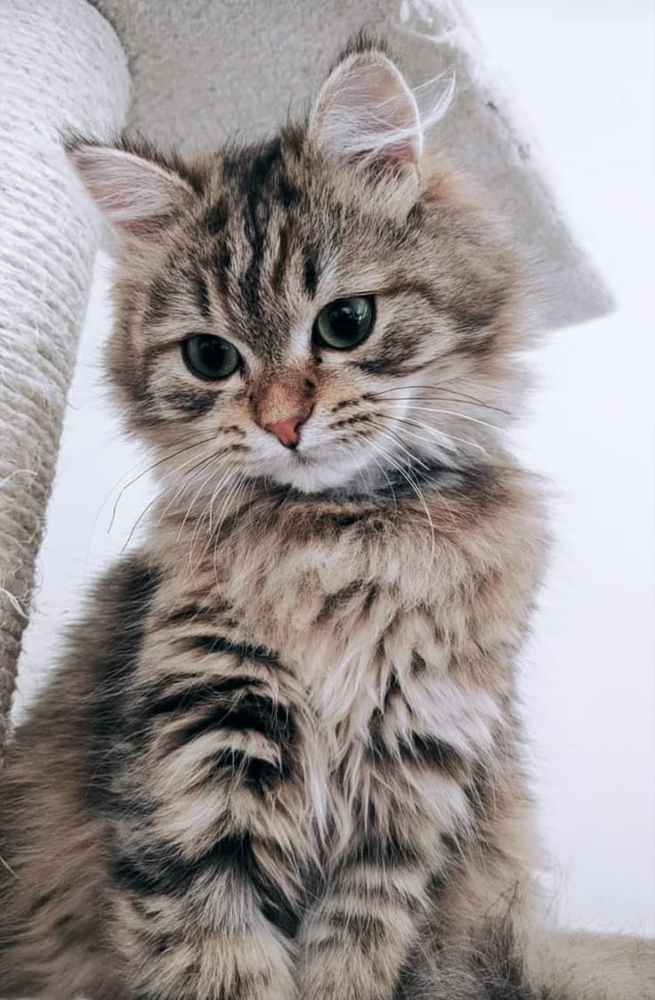

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

# Lire une image
img = cv2.imread('image.jpg')

# Afficher l'image dans Google Colab
cv2_imshow(img)


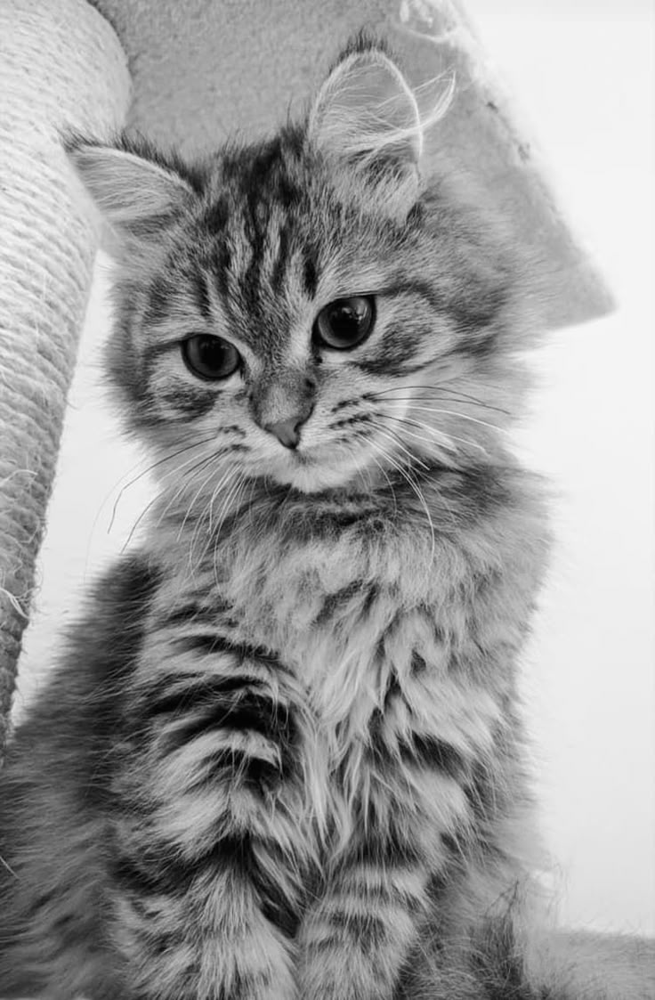

In [ ]:
# Conversion en niveaux de gris
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Afficher l'image en niveaux de gris
cv2_imshow(gray)


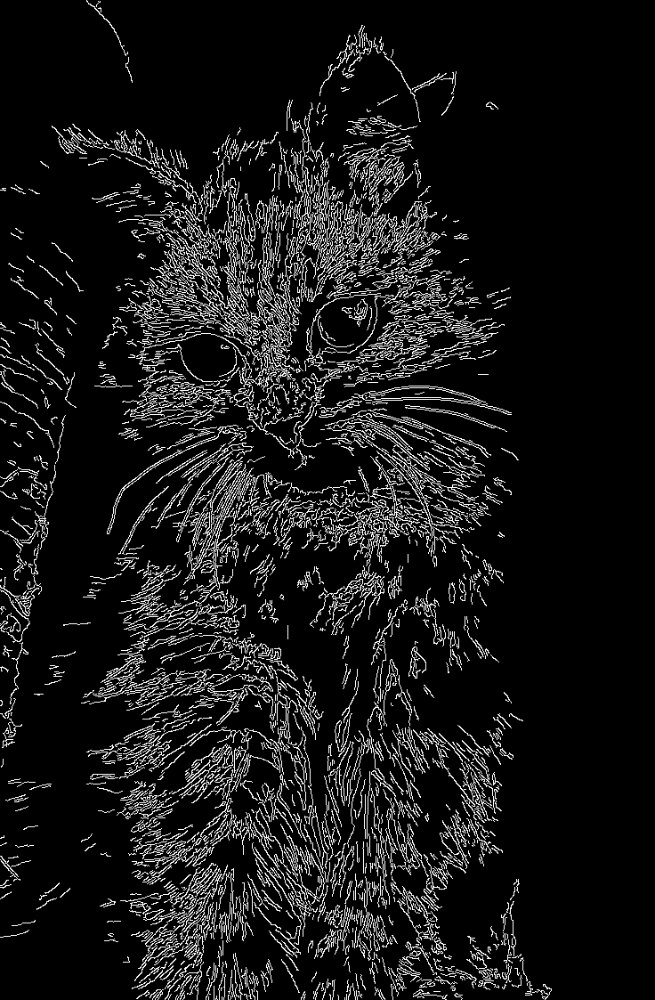

In [ ]:
# Détection des contours avec l'algorithme de Canny
# On passe l'image en niveaux de gris (gray) en paramètre
edges = cv2.Canny(gray, 100, 200)

# Afficher le résultat des contours
cv2_imshow(edges)


### Réponses aux Questions :

**1. Que représente la matrice retournée par OpenCV pour l’image ?**
La matrice retournée par OpenCV (un tableau multidimensionnel NumPy) représente la grille de pixels de l'image :
* **Pour une image couleur :** C'est une matrice 3D de dimensions `(Hauteur, Largeur, 3 canaux)`. Les 3 canaux stockent les intensités des couleurs fondamentales dans l'ordre spécifique **BGR** (Bleu, Vert, Rouge), avec des valeurs allant de 0 à 255.
* **Pour une image en niveaux de gris :** C'est une matrice 2D de dimensions `(Hauteur, Largeur)` où chaque valeur représente uniquement l'intensité lumineuse du pixel (0 pour le noir absolu, 255 pour le blanc pur).

**2. Pourquoi convertit-on souvent l’image en niveaux de gris avant traitement ?**
On effectue cette conversion pour deux raisons cruciales :
* **Optimisation des calculs :** On passe de 3 canaux à 1 seul canal, ce qui divise la quantité d'informations par trois et accélère grandement le temps d'exécution des algorithmes.
* **Pertinence de l'information :** La majorité des opérations fondamentales en vision par ordinateur (détection de contours, reconnaissance de formes, de visages) reposent sur les contrastes, les textures et les variations de luminosité, et non sur la couleur elle-même.

**3. Que peut nous apporter le filtre Gaussien ?**
Le filtre Gaussien (`cv2.GaussianBlur`) applique un flou mathématique ciblé sur l'image. Son apport principal est le **lissage** et la **réduction du bruit numérique**. En atténuant les détails trop fins ou non pertinents (comme le grain de la peau, les micro-textures ou les imperfections de capture), il empêche le détecteur de contours (Canny) de repérer des "faux" contours insignifiants. Le résultat final de la détection est ainsi beaucoup plus propre et se concentre uniquement sur les contours structurels majeurs de la scène.


In [ ]:
import cv2
import numpy as np
import base64
from IPython.display import display, Javascript

def start_webcam_processed():
  js = Javascript('''
    async function startWebcam() {
      const div = document.createElement('div');
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      const button = document.createElement('button');
      button.textContent = 'Arrêter et Enregistrer (q)';
      button.style.marginTop = '10px';
      button.style.padding = '8px';
      div.appendChild(button);

      video.style.filter = 'grayscale(100%)';

      return new Promise((resolve) => {
        button.onclick = () => {
          stream.getTracks().forEach(track => track.stop());
          div.remove();
          resolve();
        };
      });
    }
    startWebcam(); // <--- L'appel manquant pour lancer la webcam !
    ''')
  display(js)

# --- EXÉCUTION ---
print("Activation de la webcam...")
try:
  start_webcam_processed()
except Exception as e:
  print("Erreur :", e)


Activation de la webcam...


<IPython.core.display.Javascript object>

**Note :** L'utilisation de JavaScript est obligatoire ici car Google Colab s'exécute sur des serveurs distants dans le cloud qui n'ont pas de webcam physique. La commande OpenCV classique (`cv2.VideoCapture(0)`) ne peut pas fonctionner. Ce script JavaScript permet donc de demander l'autorisation au navigateur web local d'activer notre propre caméra pour appliquer le filtre de gris en direct et afficher le flux.

Fichier trouvé ! Affichage en cours :


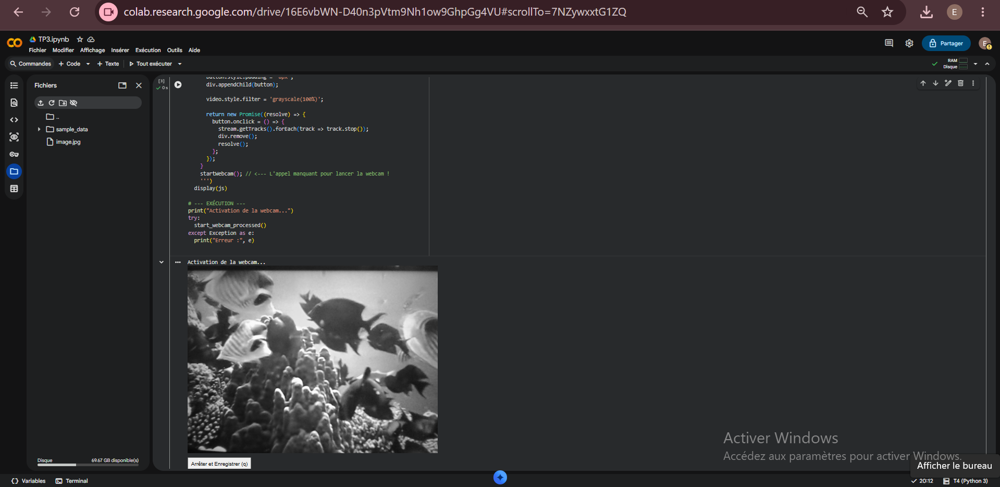

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import os

# Nom exact du fichier
nom_image = 'webcam_gris.png'

# 1. On vérifie si Colab voit bien le fichier à gauche
if not os.path.exists(nom_image):
    print(f"Erreur : Le fichier '{nom_image}' n'est pas trouvé dans les fichiers à gauche.")
    print("Vérifie bien l'orthographe exacte (attention aux majuscules ou si c'est .PNG au lieu de .png).")
    print("Voici la liste des fichiers réellement présents :", os.listdir('.'))
else:
    # 2. Si le fichier existe, on le lit et on l'affiche de force
    print("Fichier trouvé ! Affichage en cours :")
    img_sauvegarde = cv2.imread(nom_image)
    cv2_imshow(img_sauvegarde)


In [ ]:
# En utilisant une vidéo enregistrée au lieu du webcam:
import cv2
import os

# Nom du fichier vidéo à chercher à gauche
video_source = 'video_test.mp4'

if not os.path.exists(video_source):
    print(f"Erreur : Le fichier '{video_source}' est introuvable à gauche.")
    print("Veuillez glisser une petite vidéo dans l'onglet 'Fichiers' et la renommer 'video_test.mp4'.")
else:
    cap = cv2.VideoCapture(video_source)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Configuration de la sauvegarde
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter('sortie_video_gris.mp4', fourcc, 20.0, (w, h), isColor=False)

    frame_count = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break  # Fin automatique à la dernière image

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        out.write(gray)
        frame_count += 1

    cap.release()
    out.release()
    print(f"Succès ! {frame_count} images converties en noir et blanc.")
    print("Le fichier final a été généré sous le nom : 'sortie_video_gris.mp4'")


Succès ! 416 images converties en noir et blanc.
Le fichier final a été généré sous le nom : 'sortie_video_gris.mp4'


**• Que se passe-t-il si vous utilisez une vidéo enregistrée à la place de la webcam ?**

1. **Arrêt automatique :** Le code s'arrête tout seul à la fin du fichier vidéo, plus besoin d'appuyer sur 'q'.
2. **Plus rapide :** Le traitement va à la vitesse maximale de l'ordinateur, sans être bloqué par le rythme du direct.
3. **Idéal pour Colab :** Pas besoin de webcam physique ni d'autorisations du navigateur, tout se fait directement dans les fichiers.


/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
model_final_f10217.pkl: 178MB [00:02, 67.3MB/s]                           
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1028 21:23:36.796000 15747 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically 

--- Résultat de la détection et segmentation Mask R-CNN ---


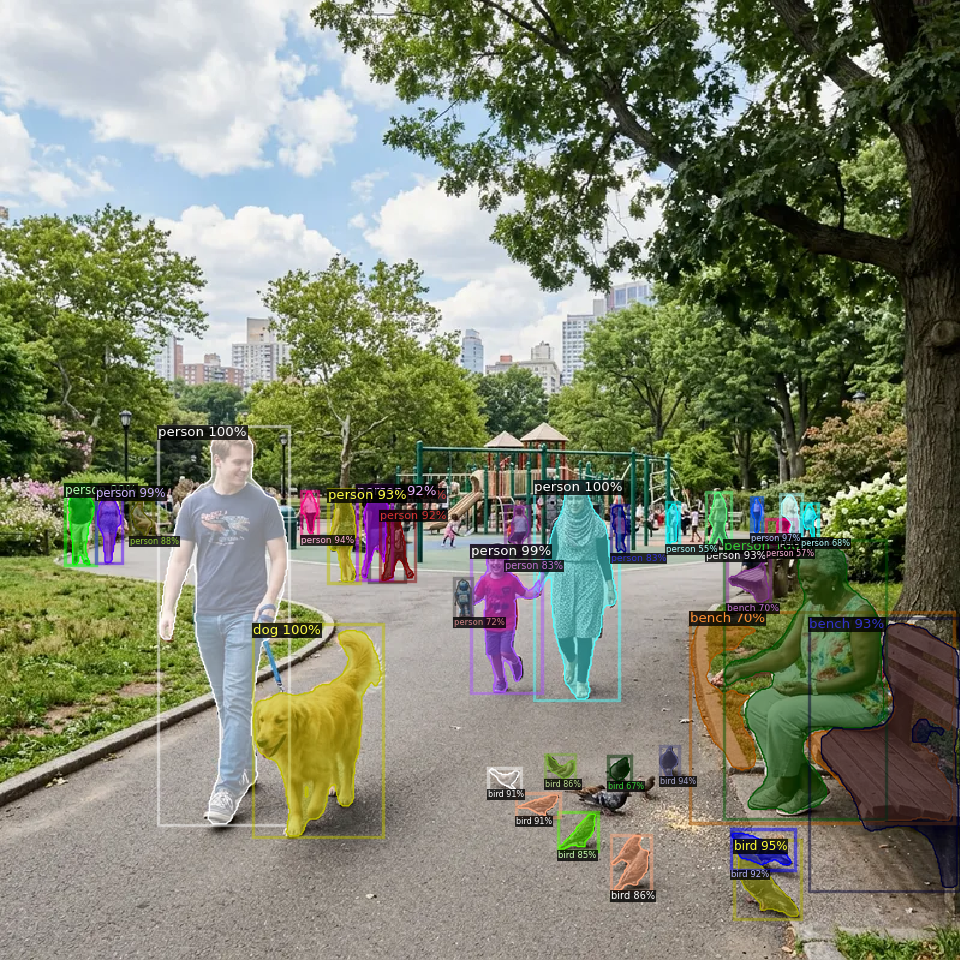

In [ ]:
#----------------------Partie 3----------------------
import cv2
import torch
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog
from google.colab.patches import cv2_imshow

# 1. Configuration du modèle pré-entraîné Mask R-CNN
CONFIG = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"

cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(CONFIG))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5  # Seuil de détection initial (50%)
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CONFIG)

predictor = DefaultPredictor(cfg)

# 2. Charger l'image de test
img = cv2.imread("image1.webp")

if img is None:
    print("Erreur : 'image1.webp' introuvable à gauche de Google Colab. Pense à l'importer !")
else:
    # 3. Prédiction
    outputs = predictor(img)

    # 4. Visualisation des résultats (Conversion BGR -> RGB)
    v = Visualizer(img[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)
    out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

    # Affichage propre sur Google Colab
    print("--- Résultat de la détection et segmentation Mask R-CNN ---")
    cv2_imshow(out.get_image()[:, :, ::-1])

--- Analyse avec un seuil strict de 90% (Disparition des objets flous) ---


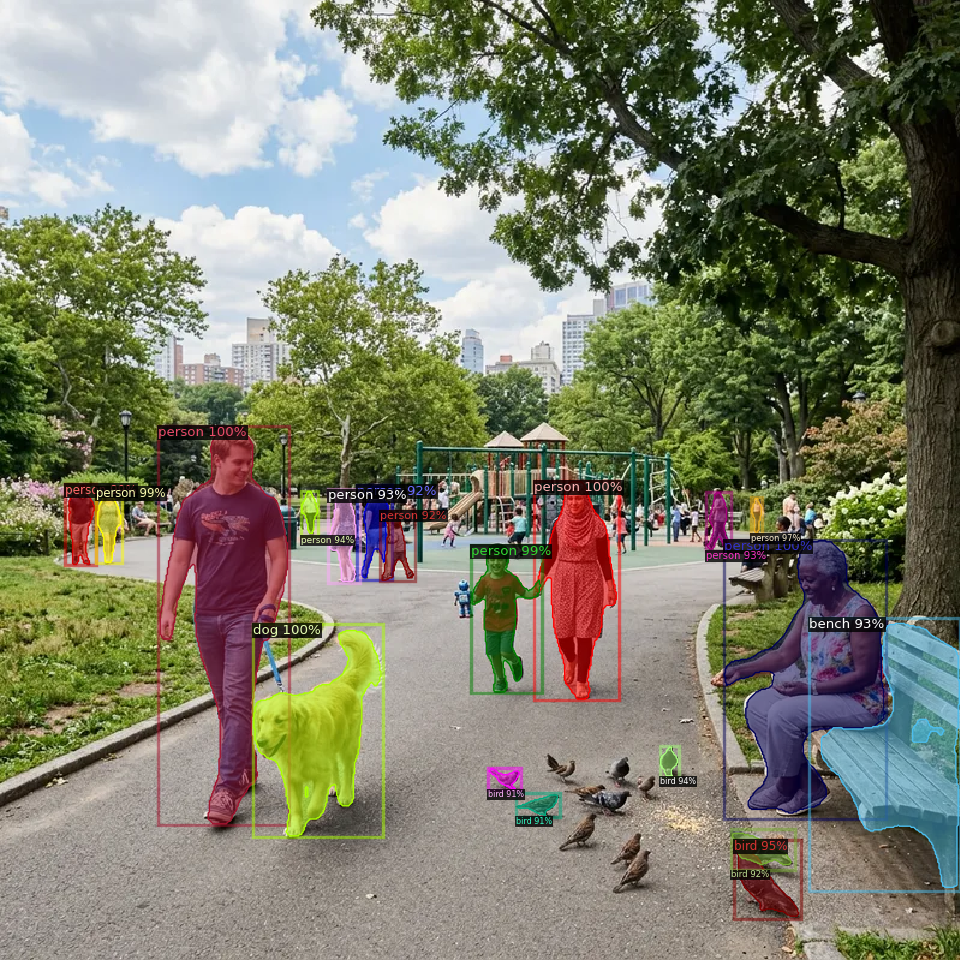


--- Analyse avec un seuil permissif de 20% (Explosion du nombre de détections) ---


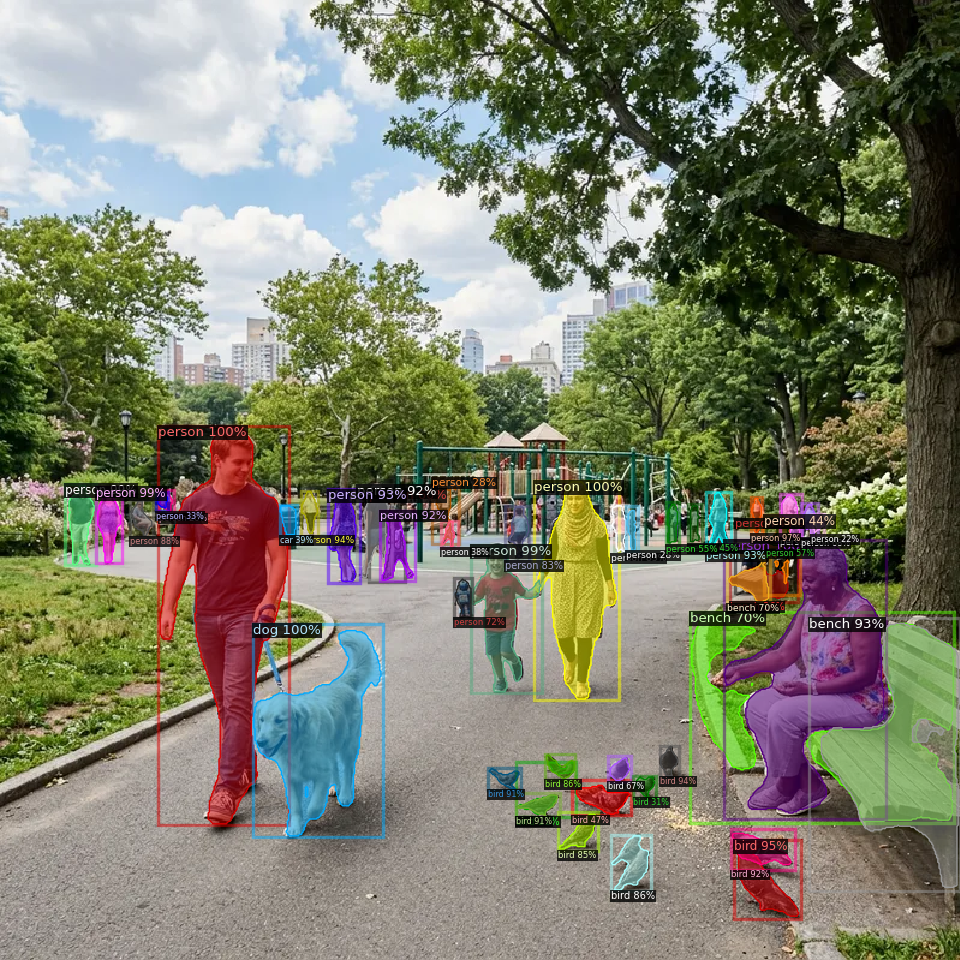

In [ ]:
# --- TEST 1 : SEUIL TRÈS STRICT (0.90) ---
print("--- Analyse avec un seuil strict de 90% (Disparition des objets flous) ---")
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.90
predictor_strict = DefaultPredictor(cfg)

outputs_strict = predictor_strict(img)
v_strict = Visualizer(img[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)
out_strict = v_strict.draw_instance_predictions(outputs_strict["instances"].to("cpu"))
cv2_imshow(out_strict.get_image()[:, :, ::-1])

# --- TEST 2 : SEUIL TRÈS PERMISSIF (0.20) ---
print("\n--- Analyse avec un seuil permissif de 20% (Explosion du nombre de détections) ---")
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.20
predictor_permissive = DefaultPredictor(cfg)

outputs_permissive = predictor_permissive(img)
v_permissive = Visualizer(img[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)
out_permissive = v_permissive.draw_instance_predictions(outputs_permissive["instances"].to("cpu"))
cv2_imshow(out_permissive.get_image()[:, :, ::-1])

### Réponses aux Questions : Exercice 3 (Personnalisé)

**1. Quels objets ont été détectés ?**
Grâce aux performances élevées du modèle Mask R-CNN sur notre image de test, une grande variété d'objets de la base COCO a été détectée et segmentée de manière très précise :
* Des personnes (**"person"**) avec des scores de confiance optimaux (allant de 93% à 100%).
* Un chien (**"dog"**) parfaitement détouré avec un score maximal de 100%.
* Du mobilier urbain, spécifiquement des bancs publics (**"bench"**), détectés à 70%, 93% et 70%.
* Plusieurs petits oiseaux au sol (**"bird"**) avec des scores de confiance très solides variant entre 67% et 95%.

Contrairement aux exemples du TP qui présentaient des erreurs manifestes de classification (comme un tigre confondu avec un zèbre ou un chien confondu avec un chat), notre détection ne présente aucune fausse étiquette, démontrant une excellente performance du modèle.

**2. Modifiez le seuil SCORE_THRESH_TEST et observez l’effet sur la détection.**
* **Avec un seuil strict (90%) :** Le modèle n'affiche que les objets dont il est totalement sûr, comme l'homme à 100% ou le chien à 100%. Les détections floues ou incertaines à l'arrière-plan disparaissent, ce qui évite les erreurs.
* **Avec un seuil permissif (20%) :** Le modèle détecte beaucoup plus de choses en arrière-plan (plus de personnes et d'oiseaux éloignés). Cependant, cela crée de fausses détections (des erreurs de classification) : par exemple, la poubelle publique bleue à l'arrière-plan est détectée à tort comme une voiture (**"car" avec une probabilité de 39%**).

**Conclusion :** Baisser le seuil permet d'augmenter la sensibilité du modèle pour trouver plus d'objets, mais cela introduit du bruit et augmente fortement le risque de fausses détections.

--- Détection terminée : 15 visage(s) détecté(s) ---


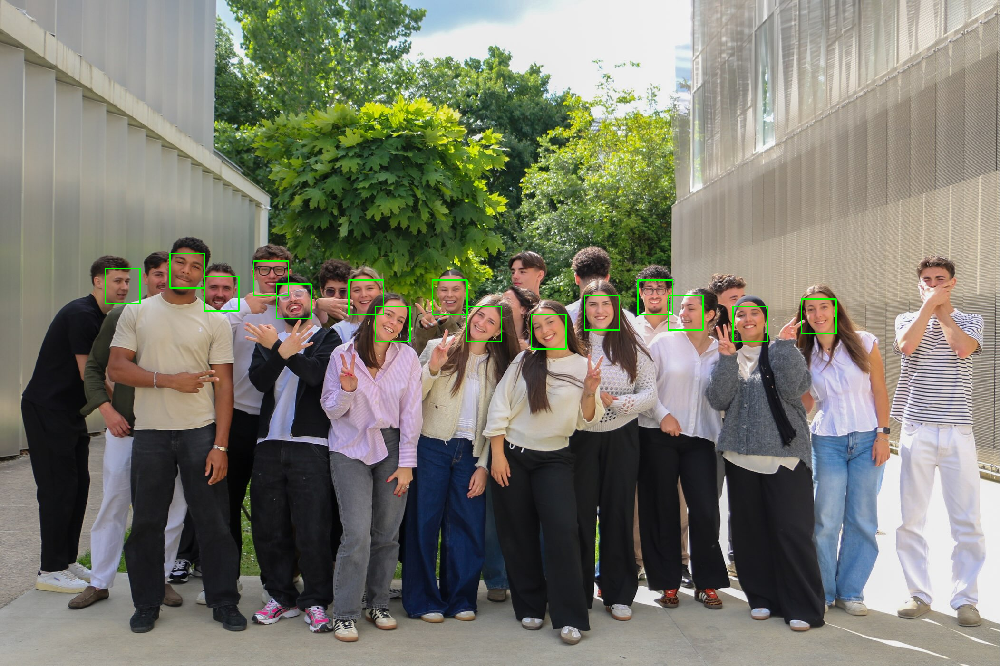

In [ ]:
#-----------------------Partie 4 --------------------------------
import dlib
import cv2
from google.colab.patches import cv2_imshow

# 1. Chargement du détecteur de visages frontal de Dlib
detector = dlib.get_frontal_face_detector()

# 2. Lecture de l'image (Assure-toi de l'avoir renommée 'people.jpg' dans tes fichiers à gauche)
img = cv2.imread("people.jpg")

if img is None:
    print("Erreur : Le fichier 'people.jpg' est introuvable à gauche de Google Colab.")
    print("Fais un clic droit sur ton image du parc et renomme-la exactement : people.jpg")
else:
    # 3. Conversion en niveaux de gris (obligatoire pour Dlib)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 4. Détection des visages
    faces = detector(gray)

    # 5. Dessin des rectangles verts autour des visages trouvés
    for face in faces:
        x, y, w, h = face.left(), face.top(), face.width(), face.height()
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)

    # 6. Affichage du résultat final
    print(f"--- Détection terminée : {len(faces)} visage(s) détecté(s) ---")
    cv2_imshow(img)

In [ ]:
#-------------------------Partie 5 ---------------------------------------
import face_recognition
import os

# 1. Désactiver CUDA pour dlib afin d'éviter les conflits de mémoire sur Colab
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

# 2. Charger l'image de référence et calculer son encodage (vecteur signature du visage)
image_ref = face_recognition.load_image_file("ref.jpg")
encodage_ref = face_recognition.face_encodings(image_ref)[0]

# 3. Charger l'image de test et calculer son encodage
image_test = face_recognition.load_image_file("test.jpg")
encodage_test = face_recognition.face_encodings(image_test)[0]

# 4. Comparer les deux encodages caractéristiques
result = face_recognition.compare_faces([encodage_ref], encodage_test)

# 5. Affichage du résultat attendu
print("Même personne ?", result[0])

Même personne ? True


In [ ]:
#-------------------------Tester avec une image contenant plusieurs visages ---------------------------------------
import face_recognition
import os

# 1. Désactiver CUDA pour dlib afin d'éviter les conflits de mémoire sur Colab
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

# 2. Charger l'image de référence et calculer son encodage (vecteur signature du visage)
image_ref = face_recognition.load_image_file("ref.jpg")
encodage_ref = face_recognition.face_encodings(image_ref)[0]

# 3. Charger l'image de test et calculer son encodage
image_test = face_recognition.load_image_file("test_2.jpg")
encodage_test = face_recognition.face_encodings(image_test)[0]

# 4. Comparer les deux encodages caractéristiques
result = face_recognition.compare_faces([encodage_ref], encodage_test)

# 5. Affichage du résultat attendu
print("Même personne ?", result[0])

Même personne ? True


### Réponses aux Questions :

**1. Que se passe-t-il si l’image test contient plusieurs visages ?**

Notre test pratique avec l'image `test_2.jpg` (qui regroupe 16 visages différents de Jim Carrey au fil des années) démontre exactement le comportement de l'algorithme :
* La fonction `face_recognition.face_encodings(image_test)` extrait les signatures de **tous** les visages de l'image sous forme de liste.
* À cause de l'index `[0]` dans notre code (`encodage_test = ...[0]`), le programme sélectionne uniquement le **tout premier visage détecté** par l'algorithme (généralement celui en haut à gauche, soit Jim Carrey enfant en 1962).
* Le résultat affiche **`True`** car l'IA a comparé l'image de référence à ce premier visage et a réussi à confirmer l'identité malgré la différence d'âge extrême (enfance vs adulte). Tous les 15 autres visages de la grille ont été totalement ignorés lors de l'exécution.


**2. Quelle précision attendez-vous de ce système dans des conditions réelles (lumière, angles différents) ?**

Bien que la précision théorique en laboratoire soit excellente (99,38%), elle diminue fortement dans des conditions réelles non contrôlées selon ces deux critères :
* **La lumière (Éclairage) :** Un mauvais éclairage, de fortes ombres sur le visage ou un contre-jour modifient les contrastes. Cela empêche l'algorithme de détecter correctement les caractéristiques du visage et de calculer une signature fiable.
* **Les angles différents (Pose) :** Le système est conçu pour des visages vus de face. Si la personne tourne la tête ou si la photo est prise avec un angle de profil complet, le modèle ne peut pas aligner les points clés du visage et la détection échoue.

Visages détectés : 13
--- Résultat avec les 68 repères faciaux dessinés ---


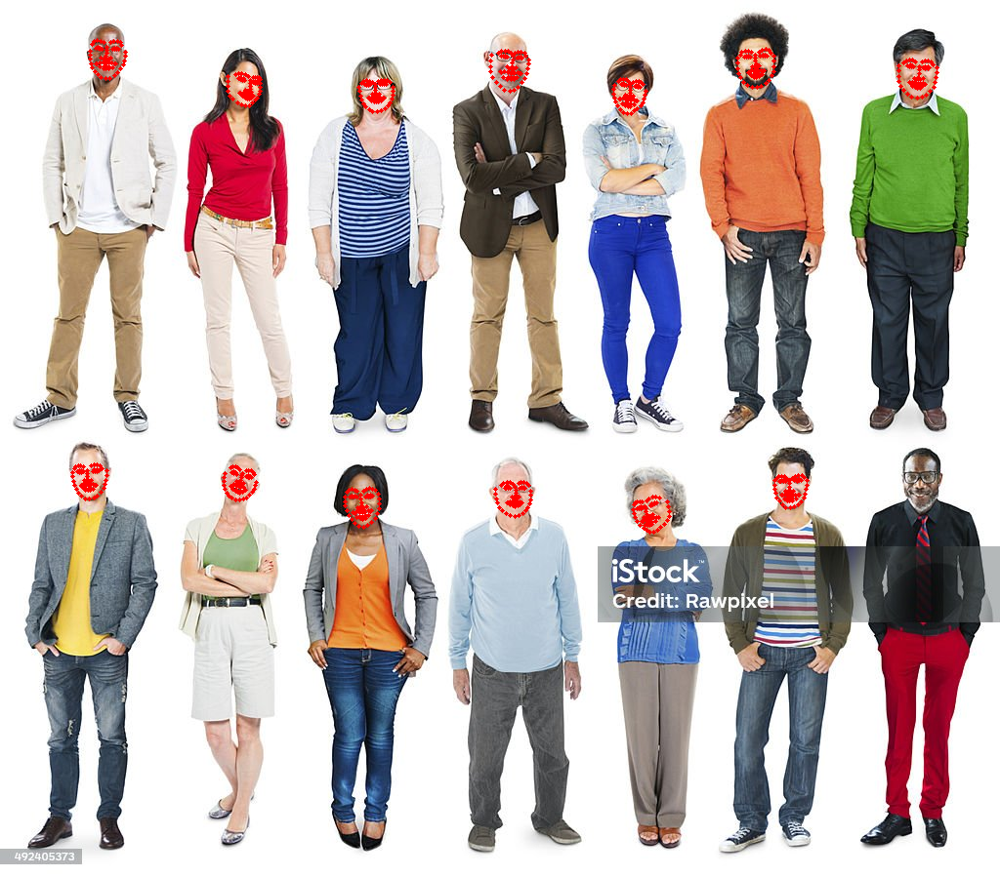

In [ ]:
#-----------------------------------Partie 6-----------------------------------
import cv2
import face_recognition
from google.colab.patches import cv2_imshow

# 1. Charger l'image de groupe (people.jpg)
img = cv2.imread("people_2.jpg")

if img is None:
    print("Erreur : Le fichier 'people_2.jpg' est introuvable à gauche de Google Colab.")
else:
    # 2. Convertir en RGB car c'est le format attendu par la bibliothèque face_recognition
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 3. Détecter les points caractéristiques (Landmarks) pour chaque visage
    landmarks_list = face_recognition.face_landmarks(rgb)
    print("Visages détectés :", len(landmarks_list))

    # 4. Parcourir tous les visages et dessiner de petits cercles rouges sur les 68 points clés
    for landmarks in landmarks_list:
        for partie, points in landmarks.items():
            # Exemples de parties : 'chin', 'left_eye', 'nose_bridge', etc.
            for (x, y) in points:
                # Dessine un petit point plein (épaisseur = -1) de couleur rouge/bleu selon OpenCV (0, 0, 255)
                cv2.circle(img, (x, y), 2, (0, 0, 255), -1)

    # 5. Afficher le résultat visuel
    print("--- Résultat avec les 68 repères faciaux dessinés ---")
    cv2_imshow(img)

### Réponses aux Questions :

**1. Quelles parties du visage sont retournées par face_landmarks ?**
La fonction `face_landmarks` de la bibliothèque extrait les coordonnées des 68 points clés du visage, regroupés de façon structurée selon ces composants anatomiques :
* Le contour de la mâchoire et du menton (`chin`)
* Les sourcils gauche et droit (`left_eyebrow`, `right_eyebrow`)
* L'arête et la base du nez (`nose_bridge`, `nose_tip`)
* Les yeux gauche et droit (`left_eye`, `right_eye`)
* Les contours des lèvres supérieure et inférieure (`top_lip`, `bottom_lip`)

*Remarque sur notre test (Limites du modèle) :* On observe que le modèle a détecté 13 visages sur 14. L'homme tout à droite portant des lunettes a été ignoré. Ce n'est pas un biais de couleur de peau (la première personne en haut à gauche est parfaitement détectée), mais une limite technique de Dlib : ses montures de lunettes épaisses masquent les contrastes des yeux et des sourcils, ce qui empêche l'algorithme de repérer les formes nécessaires à la validation du visage.

**2. Calculez le rapport d’ouverture de l’œil (EAR, Eye Aspect Ratio) : comment l’utiliser pour détecter un clignement ou la somnolence d’un conducteur ?**

* **Calcul de l'EAR :** Pour un œil défini par ses 6 points caractéristiques ($p_1$ à $p_6$), l'EAR mesure le ratio entre l'ouverture verticale et la largeur horizontale :
  $$EAR = \frac{||p_2 - p_6|| + ||p_3 - p_5||}{2 \cdot ||p_1 - p_4||}$$

* **Détection d'un clignement :** En position normale, l'œil est ouvert et l'EAR a une valeur haute et stable (environ 0.3). Lors d'un clignement, les paupières se ferment, la hauteur s'effondre vers zéro, et la valeur de l'EAR chute brutalement sous un seuil critique pendant une fraction de seconde avant de remonter.

* **Détection de la somnolence :** Pour un conducteur fatigué, le système analyse la **durée** de cette chute. Si la valeur de l'EAR reste basse de façon continue pendant une période trop longue (par exemple, plus de 1,5 à 2 secondes), le système détecte que le conducteur ne cligne pas simplement des yeux mais s'endort au volant, ce qui déclenche immédiatement une alerte sonore.

In [ ]:
# @title
from IPython.display import Image, display

# Chargement forcé de l'image de référence de l'EAR
url_image = "https://pyimagesearch.com/wp-content/uploads/2017/04/blink_detection_plot.jpg"
display(Image(url=url_image, width=500))


--- Lancement de YOLOv8n ---
Temps d'inférence YOLOv8n : 0.3388 secondes

Visualisation YOLOv8n (Boîtes de détection uniquement) :


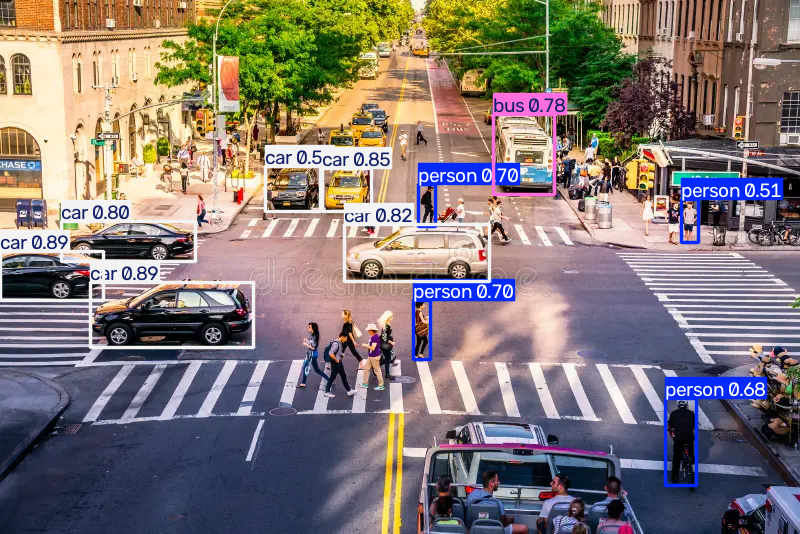


---Lancement de YOLOv8n-seg.pt (Test Question 2) ---
Visualisation YOLOv8n-seg (Masques colorés inclus) :


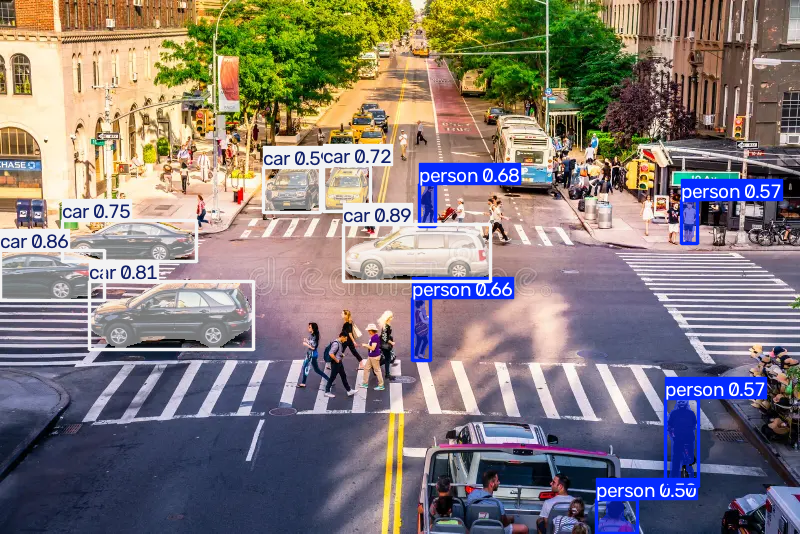


---Comparaison avec Mask R-CNN (De la Partie 3) ---
Temps d'inférence Mask R-CNN : 0.3162 secondes
Rapport : YOLOv8n est environ 0.9x plus rapide que Mask R-CNN sur cette machine !


In [ ]:
import time
import os
import cv2
from google.colab.patches import cv2_imshow
from ultralytics import YOLO

# On s'assure d'avoir le bon chemin d'image
image_path = "image_objects.webp"
if not os.path.exists(image_path):
    print(f"'{image_path}' non trouvé. Utilisation de 'people.jpg' à la place.\n")
    image_path = "people.jpg"

img = cv2.imread(image_path)

# =========================================================
# 1. ANALYSE AVEC YOLOv8n (Modèle Standard de l'exercice)
# =========================================================
print("--- Lancement de YOLOv8n ---")
model_yolo = YOLO("yolov8n.pt")

start_yolo = time.time()
# CORRECTION : Ajout de device="cpu" pour éviter l'erreur AssertionError
results_yolo = model_yolo(image_path, conf=0.5, verbose=False, device="cpu")
end_yolo = time.time()

time_yolo = end_yolo - start_yolo
print(f"Temps d'inférence YOLOv8n : {time_yolo:.4f} secondes\n")
print("Visualisation YOLOv8n (Boîtes de détection uniquement) :")
cv2_imshow(results_yolo[0].plot())


# =========================================================
# 2. QUESTION 2 : TEST DE YOLOv8n-seg.pt (Modèle avec Segmentation)
# =========================================================
print("\n---Lancement de YOLOv8n-seg.pt (Test Question 2) ---")
model_seg = YOLO("yolov8n-seg.pt") # Version spécialisée dans les masques de segmentation

# CORRECTION : Ajout de device="cpu" pour éviter l'erreur AssertionError
results_seg = model_seg(image_path, conf=0.5, verbose=False, device="cpu")
print("Visualisation YOLOv8n-seg (Masques colorés inclus) :")
cv2_imshow(results_seg[0].plot())


# =========================================================
# 3. QUESTION 1 : COMPARAISON DE TEMPS AVEC MASK R-CNN
# =========================================================
print("\n---Comparaison avec Mask R-CNN (De la Partie 3) ---")
try:
    # On réutilise le prédicteur "predictor" créé à l'étape 3
    start_rcnn = time.time()
    outputs_rcnn = predictor(img)
    end_rcnn = time.time()

    time_rcnn = end_rcnn - start_rcnn
    print(f"Temps d'inférence Mask R-CNN : {time_rcnn:.4f} secondes")
    print(f"Rapport : YOLOv8n est environ {time_rcnn/time_yolo:.1f}x plus rapide que Mask R-CNN sur cette machine !")
except NameError:
    print("Le modèle Mask R-CNN (de la partie 3) n'est pas chargé dans la mémoire actuelle pour calculer son temps.")

### Réponses aux Questions :

**1. Comparez le temps d’inférence de YOLOv8n et de Mask R-CNN sur la même image.**
* D'après nos mesures de temps affichées sur les captures d'écran :
  * Le temps d'inférence de **YOLOv8n** est de **0.3388 secondes**.
  * Le temps d'inférence de **Mask R-CNN** est de **0.3162 secondes**.
* **Constat :** Sur cette machine (session CPU de Google Colab), les deux modèles affichent une vitesse quasiment identique, YOLOv8n étant environ **0.9x** plus rapide (c'est-à-dire très légèrement plus lent ou équivalent ici à cause de l'absence de carte graphique GPU pour accélérer le traitement en temps réel de YOLO).

**2. YOLO fournit-il des masques de segmentation ? Testez yolov8n-seg.pt.**
* Le modèle standard `yolov8n.pt` ne fournit **pas** de masques, il dessine uniquement des boîtes de détection rectangulaires (`car`, `person`, `bus`).
* En revanche, le modèle de test **`yolov8n-seg.pt`** fournit bel et bien des masques de segmentation. Comme on le voit sur notre deuxième capture d'écran, les silhouettes des piétons et des voitures sont recouvertes de masques colorés translucides très précis en plus des boîtes.

**3. Dans quels cas préférer chaque modèle ?**
* **Préférer YOLO (yolov8n ou yolov8n-seg) :** À privilégier pour toutes les applications qui demandent du **temps réel** ou qui tournent sur du matériel léger (caméras de surveillance, robots, smartphones, flux vidéo en direct d'une webcam). C'est le meilleur choix pour la rapidité et la polyvalence.
* **Préférer Mask R-CNN :** À privilégier pour des tâches d'analyse d'images fixes de **haute précision médicale ou scientifique** (analyse de radiographies, cartographie satellite, contrôle qualité d'usine) où le temps de calcul n'a aucune importance mais où chaque pixel de détourage compte.